In [1]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import PyComplexHeatmap as pch

from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [2]:
seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'
data_path = Path(config['DATADIR'])

# Syntax: sym_cellline_replicate
cell_line_dict=config['cell_lines']

# Counts per guide

In [30]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [32]:
# the lowest we ever detect any guide in Pools is 217
gmin = df.loc[:, pools].min(1).min()
df_ = df.loc[:, pools].min(1).reset_index()
df_['NT guide'] = df.index.isin(controls)

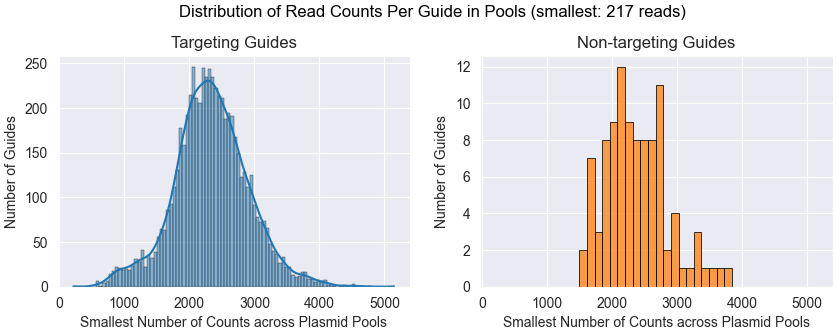

In [34]:
with sns.axes_style('darkgrid'):
    fig, axs = pl.subplots(1, 2, figsize=(10, 3), sharex=True)
ax = axs[0]
sns.histplot(df_[~df_['NT guide']], x=0, bins=100, kde=True, color='tab:blue', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title('Targeting Guides')

ax = axs[1]
sns.histplot(df_[df_['NT guide']], x=0, bins=20, kde=False, color='tab:orange', label='Non-targeting Guides', ax=ax)
ax.set_xlabel('Smallest Number of Counts across Plasmid Pools')
ax.set_ylabel('Number of Guides')
ax.set_title(f'Non-targeting Guides')

pl.suptitle(f'Distribution of Read Counts Per Guide in Pools (smallest: {gmin} reads)', y=1.05)
pl.savefig('../results/qc_plots/hist_read_counts_per_guide_in_plasmid_pools.pdf', bbox_inches='tight')
pl.show()

# Read Trimming

## Eval trimming

In [3]:
# Needs rerunning of QC eval
qcs = {x.name.split('_R1_001')[0]: pd.read_csv(x, sep='\t') for x in (Path(config['TEMPDIR']) /'pooled_screen_1/trimmed/qc').glob('*')}
df = pd.concat(qcs).droplevel(1)

ValueError: No objects to concatenate

In [103]:
df['fraction_filtered'] = df.Filtered_reads / df.Total_reads
df['cell_line'] = [x.split('-')[1] for x in df.index]
df['lane'] = [x.split('_')[-1] for x in df.index]
df['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in df.index ]
df['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in df.index ]

In [104]:
df.head()

,Mean_primer_distance,Mean_primer_certainty,Filtered_reads,Total_reads,fraction_filtered,cell_line,lane,replicate,time_point
sym-03-01-TP2_S40_L001,0.393326,0.186740,146127,3752185,0.038945,03,L001,01,TP2
sym-01-02-TP5_S14_L002,0.391821,0.192538,386904,7378938,0.052434,01,L002,02,TP5
sym-03-02-TP2_S41_L001,0.394498,0.185374,154890,3864224,0.040083,03,L001,02,TP2
sym-02-02-TP6_S35_L001,0.396969,0.182575,138160,3814596,0.036219,02,L001,02,TP6
sym-03-01-TP6_S52_L001,0.396831,0.182833,153899,4265629,0.036079,03,L001,01,TP6


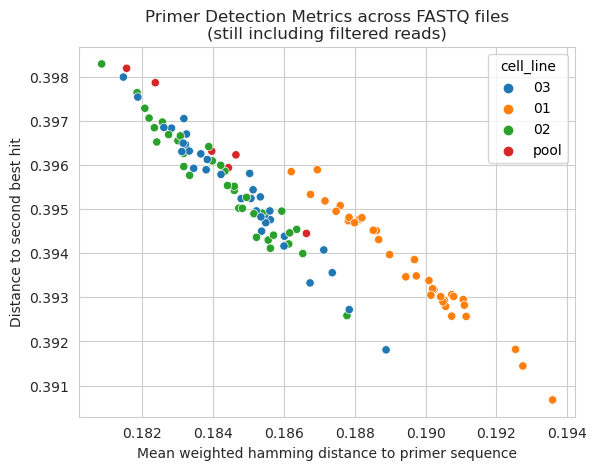

In [106]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.scatterplot(data=df, y='Mean_primer_distance', hue='cell_line', x='Mean_primer_certainty', ax=ax)
pl.xlabel('Mean weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.title('Primer Detection Metrics across FASTQ files\n(still including filtered reads)')
pl.savefig('../results/figures/trimming_qc_medians.pdf', bbox_inches='tight')
pl.show()

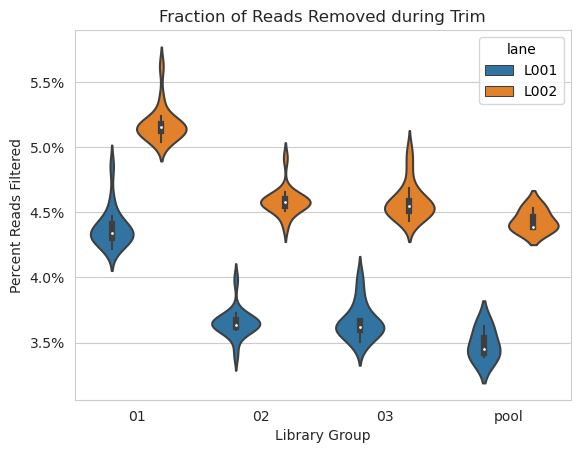

In [107]:
import matplotlib.ticker as mtick
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.violinplot(data=df, x='cell_line', hue='lane', y='fraction_filtered', ax=ax, order=['01', '02', '03', 'pool'])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1,1))
pl.ylabel('Percent Reads Filtered')
pl.xlabel('Library Group')
pl.title('Fraction of Reads Removed during Trim')
pl.savefig('../results/trimming/trimming_fraction_reads_removed.pdf', bbox_inches='tight')
pl.show()

## Finding cut-offs

In [4]:
def qual_to_float(qual):
    return list(map(ord, qual))
def make_substrings(s, K):
    return [s[i: j] for i in range(len(s)) for j in range(i + 1, len(s) + 1) if len(s[i:j]) == K]

def trim_sequence(read, quality):
    K = len(seq_primer)
    
    # search primer in expected region
    subs = make_substrings(read[pmin:pmax+K], K)
    weights = make_substrings(quality[pmin:pmax+K], K)
    primer_alignment = pd.DataFrame(index=np.arange(len(subs)), columns=['idx', 'sequence', 'hamming_distance'])
    for j, sub, w in zip(range(len(subs)), subs, weights):
        ham = hamming(list(seq_primer), list(sub), qual_to_float(w))
        primer_alignment.iloc[j] = [j+pmin, sub, ham]
    primer_alignment = primer_alignment.sort_values('hamming_distance')
    primer_idx, primer_hit, primer_distance = primer_alignment.iloc[0]
    primer_certainty = primer_alignment.hamming_distance.iloc[1] - primer_alignment.hamming_distance.iloc[0]
    
    # select guide position after primer
    trimmed_seq = read[primer_idx+K : primer_idx+K+guide_length]
    trimmed_qual = quality[primer_idx+K : primer_idx+K+guide_length]
    
    return trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty

In [5]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

In [14]:
def process(line1, line2, line3, line4):
    index = line1
    sequence = line2.replace('\n', '')
    qual = line4.replace('\n', '')

    trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
    return index, trimmed_seq, trimmed_qual

def chunker(seq, size):
    return (seq[pos:pos + size] for pos in range(0, len(seq), size))

# Parallel processing
with open(file, 'r') as INPUT:
    lines = INPUT.readlines()[:10000]  # test
    n_reads = int(len(lines) / 4)
    results = Parallel(n_jobs=4)(delayed(process)(line1, line2, line3, line4) for line1, line2, line3, line4 in tqdm(chunker(lines, size=4), total=n_reads))

# write to file
with open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    for index, trimmed_seq, trimmed_qual in tqdm(results, total=n_reads):
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

In [9]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/11277957 [00:00<?, ?it/s]

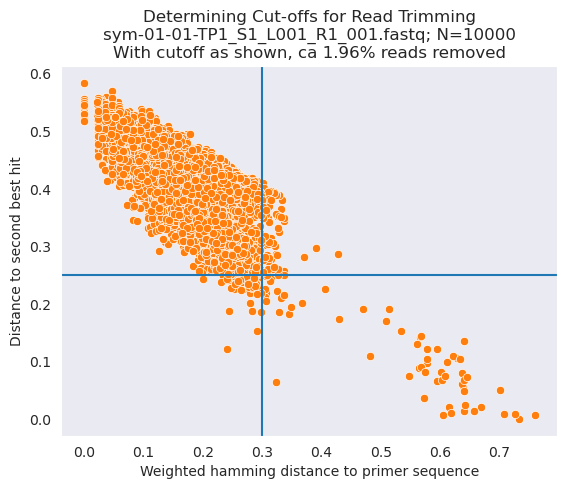

In [10]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

In [11]:
# a shallow one
file = path / 'sym-02-01-TP1_S19_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        # line 3 is just "+"
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/5025827 [00:00<?, ?it/s]

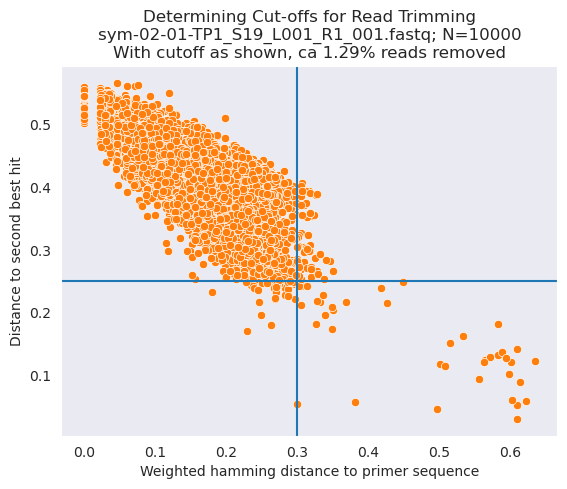

In [12]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

# Evaluate guide counting /alignment to screen

In [36]:
alignment_qc = pd.read_csv('../results/multiqc/multiqc_data/mqc_samtools_alignment_plot_1.txt', sep='\t', index_col=0)
alignment_qc['sample_id'] = [x.split('_L00')[0] for x in alignment_qc.index ]
alignment_qc = alignment_qc.groupby('sample_id').mean()  # merge lanes
alignment_qc['cell_line'] = [x.split('-')[1] for x in alignment_qc.index ]
alignment_qc['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in alignment_qc.index ]
alignment_qc['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in alignment_qc.index ]
alignment_qc['total_reads'] = alignment_qc.sum(1)
alignment_qc['fraction_mapped'] = alignment_qc['Mapped (with MQ>0)'] / alignment_qc['total_reads']
alignment_qc['cell_line_x_replicate'] = [f'{x}_{y}' for x, y in zip(alignment_qc.cell_line, alignment_qc.replicate)]

In [37]:
alignment_qc.head()

,Mapped (with MQ>0),MQ0,Unmapped,cell_line,replicate,time_point,total_reads,fraction_mapped,cell_line_x_replicate
sample_id,,,,,,,,,
Sym-pool-1-1_S55,7307020.0,16558.5,839944.5,pool,01,Pool,8163523.0,0.895082,pool_01
Sym-pool-1-2_S56,7537046.5,17021.5,869385.0,pool,02,Pool,8423453.0,0.894769,pool_02
Sym-pool-1-3_S57,10628643.0,23437.5,1195156.5,pool,03,Pool,11847237.0,0.897141,pool_03
sym-01-01-TP1_S1,9467214.5,24451.5,1199081.0,01,01,TP1,10690747.0,0.885552,01_01
sym-01-01-TP2_S4,8729435.5,22546.5,1078416.5,01,01,TP2,9830398.5,0.888004,01_01


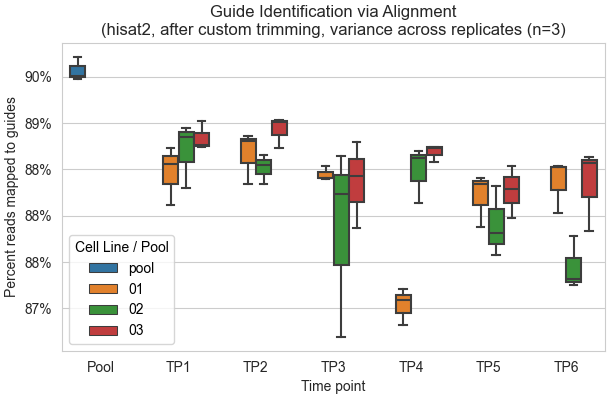

In [44]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(7,4))
sns.boxplot(data=alignment_qc.reset_index(), x='time_point', y='fraction_mapped', ax=ax, hue='cell_line', dodge=True)
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylabel('Percent reads mapped to guides')
ax.set_xlabel('Time point')
ax.set_title('Guide Identification via Alignment\n(hisat2, after custom trimming, variance across replicates (n=3)')
pl.savefig('../results/qc_plots/qc_mapping_guide_alignment.pdf', bbox_inches='tight')
pl.legend(loc='lower left', title='Cell Line / Pool')
pl.show()

# Sample Correlation

In [45]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [46]:
df

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,337,335,275,171,1198,468,334,230,156,154
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,187,155,153,117,901,319,163,106,88,93
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,865,787,762,652,1532,864,758,669,475,478


In [50]:
pairwise_correlations = pd.DataFrame(index=sample_names, columns=sample_names, dtype=float)
for i in sample_names:
    for j in sample_names:
        pairwise_correlations.loc[i, j] = np.corrcoef(df.loc[:, i], df.loc[:, j])[0, 1]

In [95]:
# # Prepare annotation
# cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
# replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
# time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
# order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# # select and reorder
# data = pairwise_correlations.loc[order, order]

# top_ha = pch.HeatmapAnnotation(
#     cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, cmap='Pastel1'),
#     time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=7, cmap='Set1'),
#     replicate=pch.anno_simple(replicate.loc[order], add_text=False),
#     verbose=0, axis=1, plot_legend=False
# )

# left_ha = pch.HeatmapAnnotation(
#     cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, cmap='Pastel1'),
#     time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=7, cmap='Set1'),
#     replicate=pch.anno_simple(replicate.loc[order], add_text=False),
#     verbose=0, axis=0, plot_legend=False
# )

# pl.figure(figsize=(15, 10))
# cm = pch.ClusterMapPlotter(
#     data=data, left_annotation=left_ha, top_annotation=top_ha,
#     row_cluster=False, col_cluster=False,
#     # rcol_split=cell_line.loc[order],
#     # col_split_gap=2,row_split_gap=1,
#     label='beta', row_dendrogram=False, col_dendrogram=False,
#     legend_gap=7, rasterized=True, cmap='rocket', vmin=0, vmax=1,
#     legend_kws=dict(label='L2FC'),
#     xlabel="Samples", ylabel='Samples', legend_hpad=0,
#     verbose=0
# )
# # pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1', y=0.92)
# # pl.savefig('../results/heatmap/count_matrix_l2fc_heatmap_simple.png', dpi=300)
# # pl.savefig('../results/heatmap/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
# pl.show()

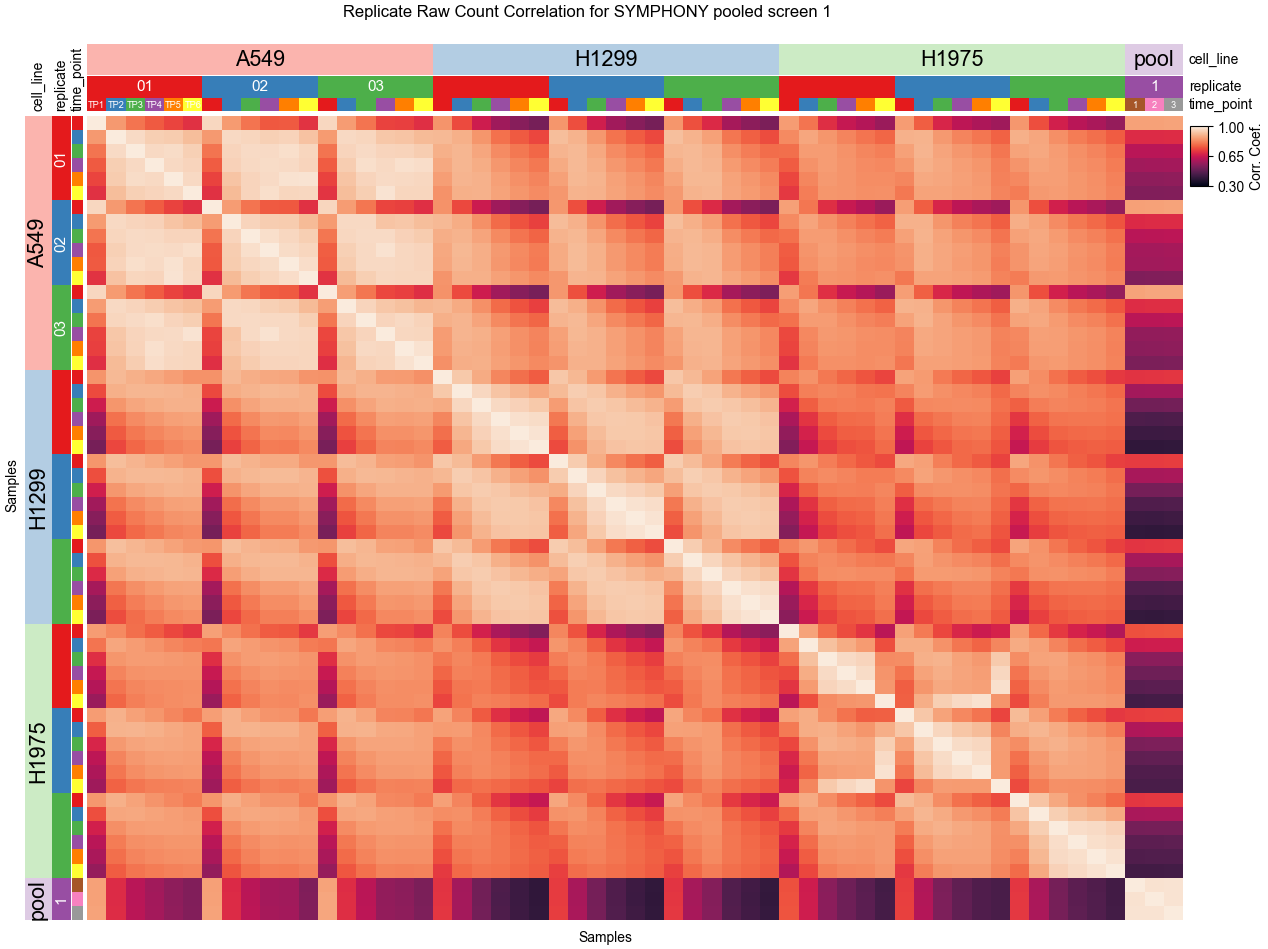

In [99]:
# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, cmap='Pastel1'),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, cmap='Set1'),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, cmap='Pastel1'),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=False, height=3, cmap='Set1'),
    verbose=0, axis=0, plot_legend=False
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    # rcol_split=cell_line.loc[order],
    # col_split_gap=2,row_split_gap=1,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=0.3, vmax=1,
    legend_kws=dict(label='Corr. Coef.'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle('Replicate Raw Count Correlation for SYMPHONY pooled screen 1', y=0.92)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.png', dpi=300)
pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.pdf', dpi=300)
pl.show()